# Homework 08: Unsupervised Learning — Discovering Structure in Data

#### Due Date: Sunday, October 25th at 11:59pm (with 2 hour plus 1 minute grace period)

#### The late policy is described in the DX 603 Syllabus.

### Introduction


In supervised learning, we train models using known target values. In **unsupervised learning**, we instead look for patterns and structure in data without telling the model what groups to find.

In this homework, you will investigate the **Dry Bean dataset**, which contains 13,611 observations from seven bean varieties. Each bean is described by 16 numerical measurements of its size and shape. Although the known varieties are available, you will not use them to train your clustering models. Instead, you will use them afterward to help interpret the groups you discover.

The central goal of this assignment is not simply to find the clustering algorithm with the highest score. Instead, you will approach clustering as an **exploratory data science investigation**: examine the data, identify interesting patterns, form hypotheses, modify your analysis, and evaluate what changes.

You will begin by applying K-Means to the complete dataset. Then, building on your initial discoveries, you will investigate how the clustering changes when you:

- Remove a distinctive population of observations.
- Use different subsets of features to define similarity.
- Eliminate highly correlated measurements.
- Apply PCA to reduce dimensionality before clustering.

Along the way, you will use silhouette scores to evaluate cluster separation and the Adjusted Rand Index (ARI) to compare different cluster assignments. You will also examine cluster composition using the known bean varieties.

**An important theme throughout the homework is that clusters depend on the data representation and modeling choices.** A clustering solution can have a high silhouette score without necessarily corresponding to the categories we would like to discover.

The homework concludes with multiple-choice questions and a reflection in which you will draw on the results of your experiments to recommend and justify a clustering approach.

As in previous assignments, use the provided answer cells for your graded answers. Store numerical results at full precision; the graded output cells will format floating-point values to four decimal places.



In [409]:
pip install seaborn


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [410]:
# Useful imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Global settings
random_seed = 42

## Load the data

We'll use UCI's `ucimlrepo` loader because it makes the provenance explicit.


In [411]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# --------------------------------------------------
# Load the Dry Bean dataset
# --------------------------------------------------

# If needed:
# !pip install -q ucimlrepo

beans = fetch_ucirepo(id=602)

# Combine numerical features and the bean variety label
df = beans.data.original.copy()

print(f"Dataset shape: {df.shape}")
print("\nBean varieties:")
print(df["Class"].value_counts())

# Features used for unsupervised learning
feature_columns = df.columns.drop(["Class"])
X = df[feature_columns].copy()


print(f"Clustering features: {X.shape[1]}")
print(f"Observations: {X.shape[0]}")

Dataset shape: (13611, 17)

Bean varieties:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
Clustering features: 16
Observations: 13611


### Basic EDA

In [412]:
X.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


In [413]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
dtypes: float64(14), int64(2)
memory usage: 1.7 MB


In [414]:
X.describe().round(2)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.0,13611.00,13611.00
mean,53048.28,855.28,320.14,202.27,1.58,0.75,53768.20,253.06,0.75,0.99,0.87,0.80,0.01,0.0,0.64,1.00
std,29324.10,214.29,85.69,44.97,0.25,0.09,29774.92,59.18,0.05,0.00,0.06,0.06,0.00,0.0,0.10,0.00
min,20420.00,524.74,183.60,122.51,1.02,0.22,20684.00,161.24,0.56,0.92,0.49,0.64,0.00,0.0,0.41,0.95
25%,36328.00,703.52,253.30,175.85,1.43,0.72,36714.50,215.07,0.72,0.99,0.83,0.76,0.01,0.0,0.58,0.99
50%,44652.00,794.94,296.88,192.43,1.55,0.76,45178.00,238.44,0.76,0.99,0.88,0.80,0.01,0.0,0.64,1.00
75%,61332.00,977.21,376.50,217.03,1.71,0.81,62294.00,279.45,0.79,0.99,0.92,0.83,0.01,0.0,0.70,1.00
max,254616.00,1985.37,738.86,460.20,2.43,0.91,263261.00,569.37,0.87,0.99,0.99,0.99,0.01,0.0,0.97,1.00


### Feature Distributions


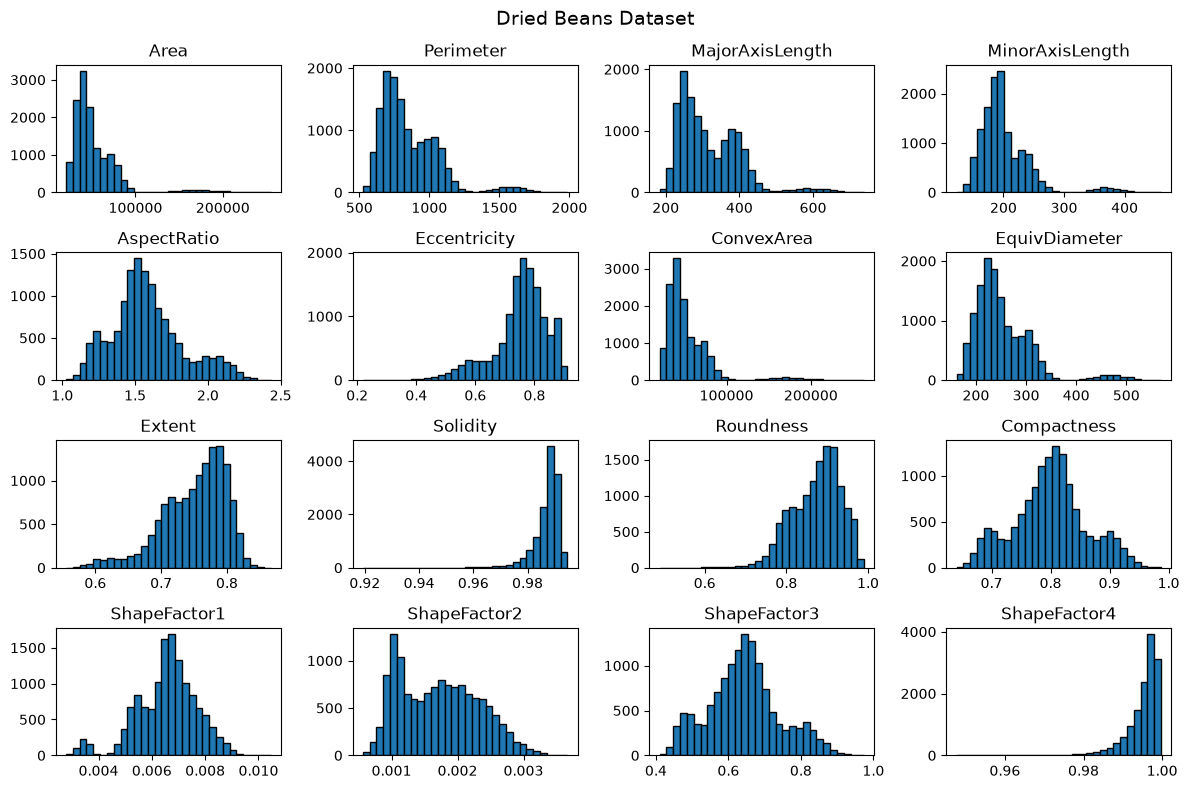

In [415]:
# --------------------------------------------------
# Distributions 
# --------------------------------------------------

X.hist(
    bins=30,
    figsize=(12, 8),
    edgecolor='black',
    grid=False
)

plt.suptitle(
    "Dried Beans Dataset",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Correlation Matrix

Correlations are useful here because several bean measurements describe closely related aspects of size and shape.

In [416]:
# --------------------------------------------------
# Correlation Matrix
# --------------------------------------------------

correlations = X.corr()

display(
    correlations.round(2)
)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.00,0.97,0.93,0.95,0.24,0.27,1.00,0.98,0.05,-0.20,-0.36,-0.27,-0.85,-0.64,-0.27,-0.36
Perimeter,0.97,1.00,0.98,0.91,0.39,0.39,0.97,0.99,-0.02,-0.30,-0.55,-0.41,-0.86,-0.77,-0.41,-0.43
MajorAxisLength,0.93,0.98,1.00,0.83,0.55,0.54,0.93,0.96,-0.08,-0.28,-0.60,-0.57,-0.77,-0.86,-0.57,-0.48
MinorAxisLength,0.95,0.91,0.83,1.00,-0.01,0.02,0.95,0.95,0.15,-0.16,-0.21,-0.02,-0.95,-0.47,-0.02,-0.26
AspectRatio,0.24,0.39,0.55,-0.01,1.00,0.92,0.24,0.30,-0.37,-0.27,-0.77,-0.99,0.02,-0.84,-0.98,-0.45
Eccentricity,0.27,0.39,0.54,0.02,0.92,1.00,0.27,0.32,-0.32,-0.30,-0.72,-0.97,0.02,-0.86,-0.98,-0.45
ConvexArea,1.00,0.97,0.93,0.95,0.24,0.27,1.00,0.99,0.05,-0.21,-0.36,-0.27,-0.85,-0.64,-0.27,-0.36
EquivDiameter,0.98,0.99,0.96,0.95,0.30,0.32,0.99,1.00,0.03,-0.23,-0.44,-0.33,-0.89,-0.71,-0.33,-0.39
Extent,0.05,-0.02,-0.08,0.15,-0.37,-0.32,0.05,0.03,1.00,0.19,0.34,0.35,-0.14,0.24,0.35,0.15
Solidity,-0.20,-0.30,-0.28,-0.16,-0.27,-0.30,-0.21,-0.23,0.19,1.00,0.61,0.30,0.15,0.34,0.31,0.70


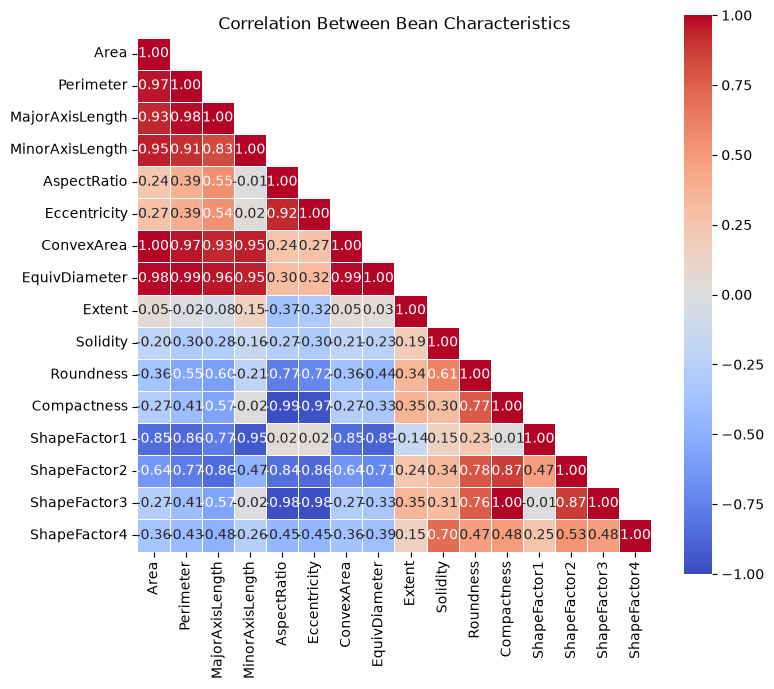

In [417]:
# --------------------------------------------------
# Correlation Matrix: Lower Triangle
# --------------------------------------------------

correlations = X.corr()

# Mask the upper triangle
mask = np.triu(
    np.ones_like(correlations, dtype=bool),
    k=1
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    correlations,
    mask=mask,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)

plt.title("Correlation Between Bean Characteristics")
plt.tight_layout()
plt.show()

### Pairplots

We'll pick a couple of features and see how the plot against each other...

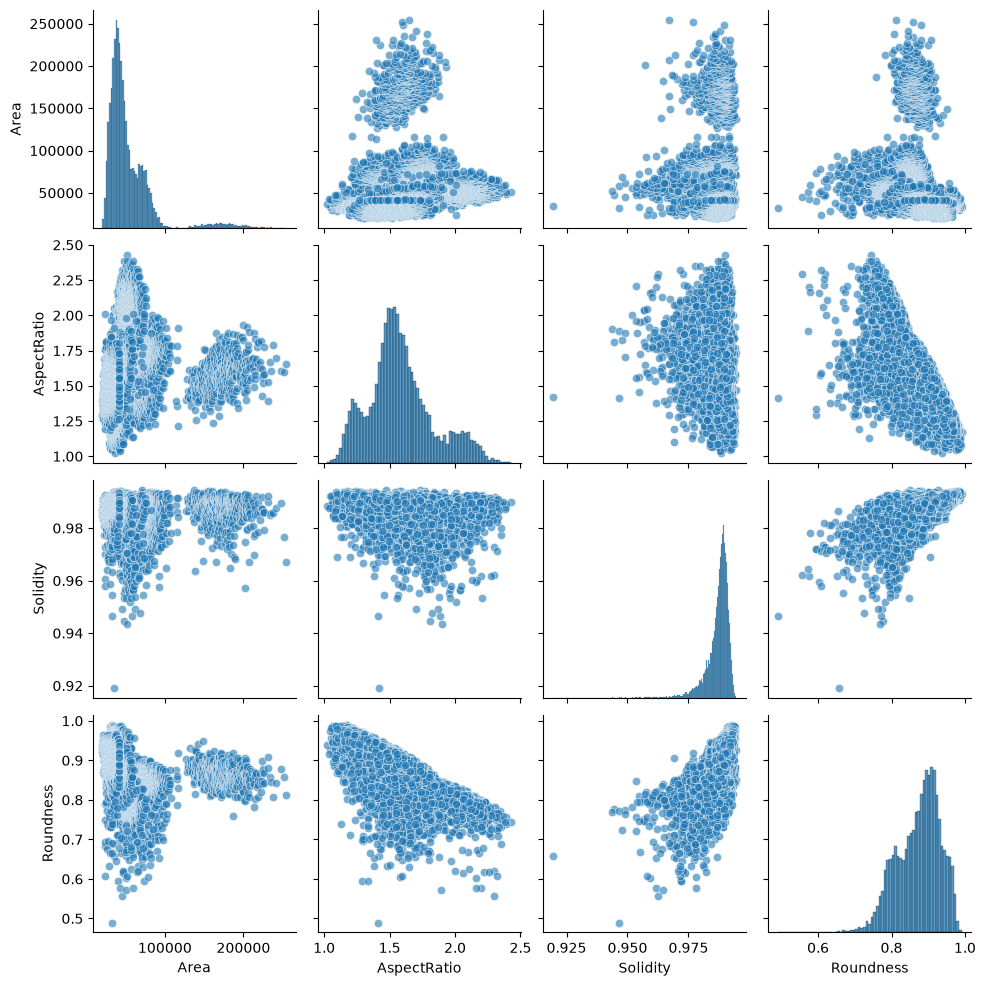

In [418]:
import seaborn as sns

pairplot_features = [
    "Area",
    "AspectRatio",
    "Solidity",
    "Roundness"
]

sns.pairplot(
    X[pairplot_features],
    diag_kind="hist",
    plot_kws={
        "alpha": 0.6,
        "s": 35
    }
)

plt.show()

### Pairplots with Classes Distinguished

We removed the target `Class` but it is instructive to look at the past plots with type of bean distinguished by color. Plus, it is very cool looking!

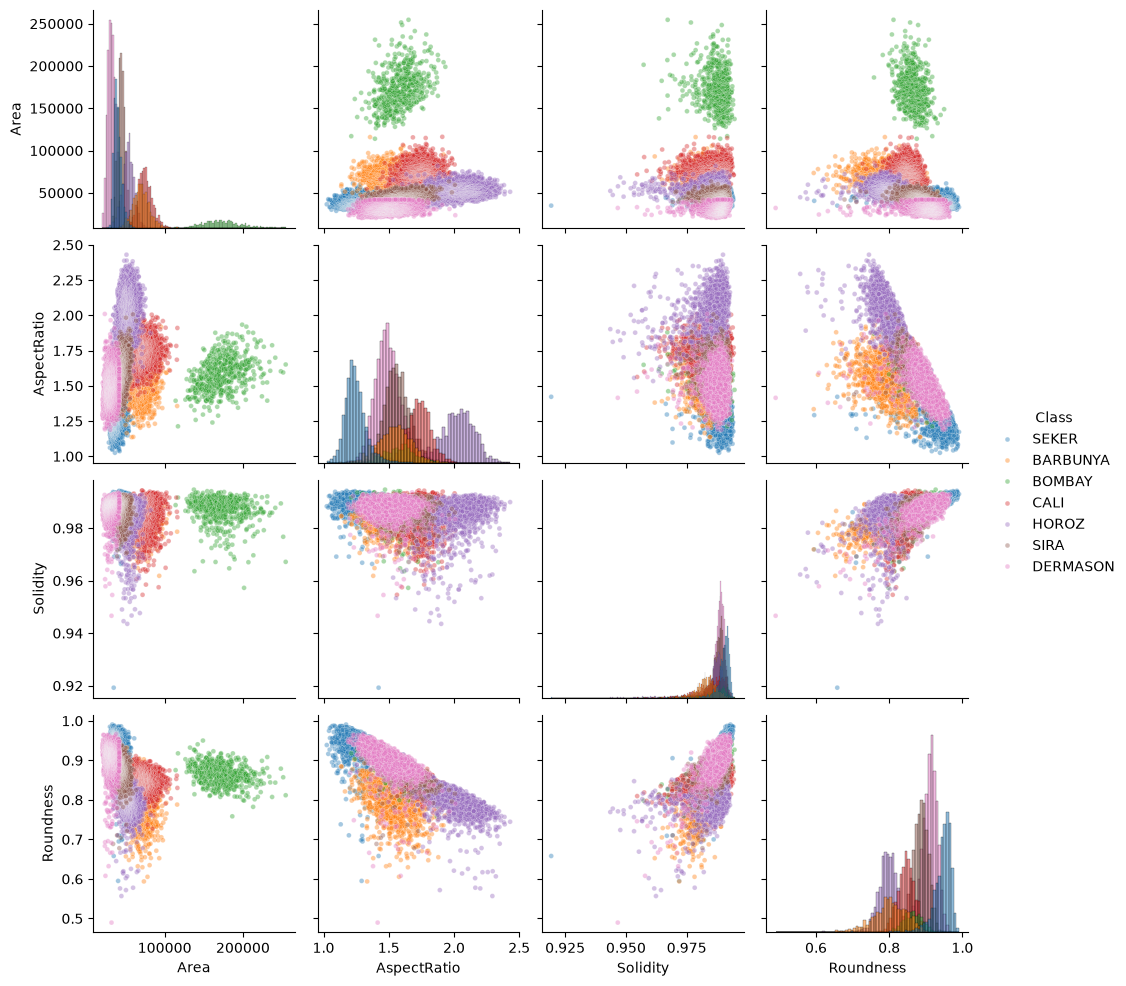

In [419]:
sns.pairplot(
    df,
    vars=pairplot_features,
    hue="Class",
    diag_kind="hist",
    plot_kws={
        "alpha": 0.4,
        "s": 12
    }
)

plt.show()

## Problem 1: Discovering Structure in the Dry Bean Dataset

The Dry Bean dataset contains measurements of **13,611 beans** belonging to seven known varieties. Each bean is described by **16 numerical features** measuring size and shape.

For this problem, your goal is to discover groups of similar beans **without using the known variety (`Class`) to fit a model**. The notebook has already loaded:

- `X`: the 16 numerical measurements, without the `Class` column.
- `df`: the original DataFrame, including `Class`, which you may use **only after clustering** to interpret the results.

### Parts A & B: Choosing the number of clusters

1. Use a `Pipeline` with `StandardScaler()` and `KMeans()` to fit models for **K = 2, 3, ..., 8**.
2. Use `n_init=10` and `random_state=42` in every K-Means model.
3. Calculate a silhouette score for each K, using **`sample_size=3000` and `random_state=42`** in `silhouette_score()` to keep the computation manageable.
4. Make a plot of silhouette score versus K.

Assign:

- **`a1a`** = the integer K with the highest sampled silhouette score.
- **`a1b`** = that silhouette score.

### Parts C–E: Investigating the smallest cluster

1. Fit a new `StandardScaler` + `KMeans` pipeline using the value of K selected above, with the same `n_init` and `random_state` settings.
2. Inspect the cluster sizes and identify the smallest cluster.
3. Make a cross-tabulation of cluster assignments versus `df["Class"]` to interpret the groups.
4. Determine which known variety occurs most frequently in the smallest cluster and calculate its proportion. Do **not** include `Class` in the clustering input.

Assign:

- **`a1c`** = the integer number of beans in the smallest cluster.
- **`a1d`** = the string name of the most common bean variety in that smallest cluster.
- **`a1e`** = the proportion of that variety within the smallest cluster (use the scale **0–1**).

*Cluster numbers are arbitrary.* Determine the smallest cluster from its size rather than assuming that it has a particular label.

### Part F: Visualizing the clusters with PCA

1. Standardize all 16 numerical features.
2. Apply `PCA(n_components=2)` to the standardized data.
3. Make a scatterplot in the two-dimensional PCA space, colored by the cluster assignments from Parts C–E.
4. Calculate the proportion of total feature variance explained by the two principal components.

PCA is used **only for visualization** here: fit K-Means on all 16 standardized features, not on the two PCA coordinates.

Assign:

- **`a1f`** = the proportion of the total feature variance explained by the first two principal components together (scale 0–1).


**IMPORTANT CODING NOTES:**

- Save the values of K being tested as `K_values` (in increasing order).
- Save the corresponding silhouette scores as `scores`.
- Save the best number of clusters as `best_k`.
- Save its silhouette score as `best_score`.

You will use these variables in Problem 2.

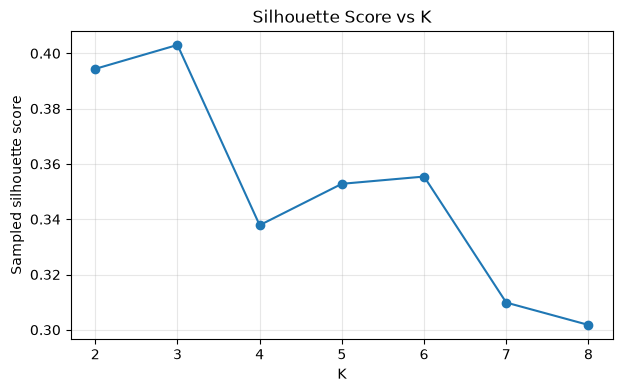

Best K: 3, silhouette: 0.4030


In [420]:
# Your code here; add as many cells as you wish

# Parts A & B: silhouette score for each K
K_values = list(range(2, 9))
scores = []

for k in K_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=42)),
    ])
    labels = pipe.fit_predict(X)
    X_scaled = pipe[:-1].transform(X)   # standardized data the clusters were fit on
    scores.append(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42))

best_idx = int(np.argmax(scores))
best_k = K_values[best_idx]
best_score = scores[best_idx]

plt.figure(figsize=(7, 4))
plt.plot(K_values, scores, marker="o")
plt.xlabel("K")
plt.ylabel("Sampled silhouette score")
plt.title("Silhouette Score vs K")
plt.grid(alpha=0.3)
plt.show()

print(f"Best K: {best_k}, silhouette: {best_score:.4f}")

In [421]:
# Parts C-E: smallest cluster at the best K
best_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=best_k, n_init=10, random_state=42)),
])
labels_full = best_pipe.fit_predict(X)

sizes = pd.Series(labels_full).value_counts()
smallest_cluster = sizes.idxmin()
print(sizes.sort_index())

# Class is used only here, after clustering, to interpret the groups.
display(pd.crosstab(labels_full, df["Class"]))

smallest_classes = df.loc[labels_full == smallest_cluster, "Class"].value_counts()
top_variety = smallest_classes.idxmax()
top_proportion = smallest_classes.max() / smallest_classes.sum()

print(f"Smallest cluster: {smallest_cluster}, size {sizes.min()}")
print(f"Most common variety: {top_variety} ({top_proportion:.4f})")

0    7579
1     524
2    5508
Name: count, dtype: int64


Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
row_0,,,,,,,
0,108,0,7,3507,19,2019,1919
1,1,522,1,0,0,0,0
2,1213,0,1622,39,1909,8,717


Smallest cluster: 1, size 524
Most common variety: BOMBAY (0.9962)


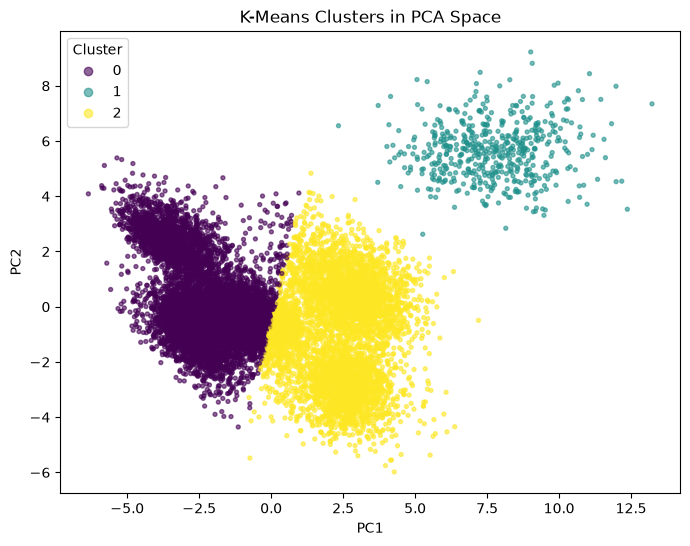

Variance explained by 2 PCs: 0.8190


In [422]:
# Part F: PCA for visualization only
X_std = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_full, cmap="viridis", s=8, alpha=0.6)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clusters in PCA Space")
plt.show()

explained_2 = pca.explained_variance_ratio_.sum()
print(f"Variance explained by 2 PCs: {explained_2:.4f}")

In [423]:
# Your answer here, NOT in the next cell

a1a = int(best_k)    # Replace with the integer K giving highest silhouette score.

In [424]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

a1a = 3


In [425]:
# Your answer here, NOT in the next cell

a1b = float(best_score)    # Replace with the highest sampled silhouette score.

In [426]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b:.4f}")

a1b = 0.4030


In [427]:
# Your answer here, NOT in the next cell

a1c = int(sizes.min())    # Replace with the number of beans in the smallest cluster.

In [428]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1c = {a1c}")

a1c = 524


In [429]:
# Your answer here, NOT in the next cell

a1d = top_variety    # Replace with the most common variety name in the smallest cluster.

In [430]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1d = {a1d}")

a1d = BOMBAY


In [431]:
# Your answer here, NOT in the next cell

a1e = float(top_proportion)    # Replace with the proportion of the smallest cluster belonging to that variety (0 to 1).

In [432]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1e = {a1e:.4f}")

a1e = 0.9962


In [433]:
# Your answer here, NOT in the next cell

a1f = float(explained_2)    # Replace with the explained variance fraction for the first two principal components (0 to 1).

In [434]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1f = {a1f:.4f}")

a1f = 0.8190


## Problem 2: What Happens When We Remove an Unusual Population?

In Problem 1, one K-Means cluster was unusually small and was dominated by a single known bean variety. A researcher might reasonably wonder whether that distinctive population influences the number of clusters suggested by the silhouette score.

We will conduct a **controlled investigation**: remove observations belonging to that variety, then repeat the same K-Means analysis. The known variety is used only to select the experimental subset and to interpret the resulting clusters.

### Part A: Construct the modified dataset

1. From `df`, remove all rows where `Class` matches your answer `a1d` from Problem 1.
2. Create a feature DataFrame, `X_no_bombay`, containing the same **16 numerical columns** as `X` and preserving the original feature order.
3. Check how many observations remain.

### Part B: Repeat the K-Means investigation

1. On `X_no_bombay`, fit a **new** `StandardScaler` + `KMeans` pipeline for each $K = 2, 3, \ldots, 8$.
2. Use `n_init=10` and `random_state=42` for every K-Means fit.
3. For each $K$, calculate `silhouette_score()` on the standardized modified dataset with `sample_size=3000` and `random_state=42`.
4. Plot the original and modified silhouette-score curves **on the same axes**. Keep the two experiments' feature preprocessing separate; fit the scaler again on the reduced dataset.
5. Choose the $K$ with the largest sampled silhouette score on the modified data.

### Part C: Examine the new clustering

1. Fit a new `StandardScaler` + `KMeans` pipeline using the selected $K$ on `X_no_bombay`.
2. Examine the number of observations in each cluster and identify the smallest cluster.
3. Cross-tabulate cluster membership against the remaining known varieties.
4. Identify the most common variety in the smallest cluster.

Remember that **cluster labels are arbitrary**: find the smallest cluster by its count, not by its numeric label.

### Assign

- `a2a`: Number of observations remaining after removing the distinctive variety (integer).
- `a2b`: Value of $K$ with the highest sampled silhouette score on the reduced data (integer).
- `a2c`: Highest sampled silhouette score on the reduced data (float).
- `a2d`: Difference **(reduced-data maximum − original-data maximum)** between the best silhouette scores, as a signed float reported to four decimal places in the graded output.
- `a2e`: Number of observations in the smallest cluster in the reduced-data best-$K$ solution (integer).
- `a2f`: Name of the most common known bean variety in that smallest cluster (string).

Do not assume that removing a visually distinctive group must improve the silhouette score. The goal is to **measure what changes** and later explain why.

**IMPORTANT CODING NOTES:** 

- Save the best number of clusters as `best_k_2`,
- its silhouette score as `best_score_2`, 
- the corresponding cluster assignments as `labels_reduced`, and
- the known varieties of the remaining observations as `remaining_classes`.

You will use these variables in later problems.


In [435]:
# Your code here; add as many cells as you wish
# Part A: remove the distinctive variety
mask = df["Class"] != a1d
X_no_bombay = X.loc[mask].reset_index(drop=True)
remaining_classes = df.loc[mask, "Class"].reset_index(drop=True)
print(f"Removed: {a1d}; observations remaining: {len(X_no_bombay)}")


Removed: BOMBAY; observations remaining: 13089


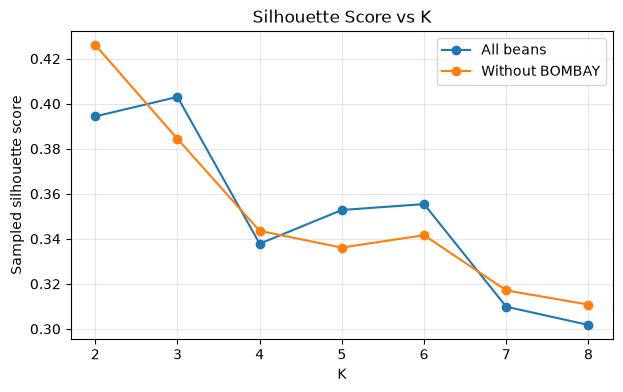

Best K (reduced): 2, silhouette: 0.4261


In [436]:
# Part B: repeat the K-Means investigation on the reduced data
scores_reduced = []

for k in K_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),   # refit on the reduced data
        ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=42)),
    ])
    labels = pipe.fit_predict(X_no_bombay)
    X_scaled = pipe[:-1].transform(X_no_bombay)
    scores_reduced.append(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42))

best_idx_2 = int(np.argmax(scores_reduced))
best_k_2 = K_values[best_idx_2]
best_score_2 = scores_reduced[best_idx_2]

plt.figure(figsize=(7, 4))
plt.plot(K_values, scores, marker="o", label="All beans")
plt.plot(K_values, scores_reduced, marker="o", label=f"Without {a1d}")
plt.xlabel("K")
plt.ylabel("Sampled silhouette score")
plt.title("Silhouette Score vs K")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Best K (reduced): {best_k_2}, silhouette: {best_score_2:.4f}")

In [437]:
# Part C: examine the new clustering
pipe_reduced = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=best_k_2, n_init=10, random_state=42)),
])
labels_reduced = pipe_reduced.fit_predict(X_no_bombay)

sizes_2 = pd.Series(labels_reduced).value_counts()
smallest_cluster_2 = sizes_2.idxmin()
print(sizes_2.sort_index())

display(pd.crosstab(labels_reduced, remaining_classes))

smallest_classes_2 = remaining_classes[labels_reduced == smallest_cluster_2].value_counts()
top_variety_2 = smallest_classes_2.idxmax()
print(f"Smallest cluster: {smallest_cluster_2}, size {sizes_2.min()}, top variety: {top_variety_2}")

0    7838
1    5251
Name: count, dtype: int64


Class,BARBUNYA,CALI,DERMASON,HOROZ,SEKER,SIRA
row_0,,,,,,
0,53,6,3544,49,2020,2166
1,1269,1624,2,1879,7,470


Smallest cluster: 1, size 5251, top variety: HOROZ


### Problem 2 Graded Questions

In [438]:
# Your answer here, NOT in the next cell

a2a = len(X_no_bombay)    # Replace with the number of remaining observations.

In [439]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 13089


In [440]:
# Your answer here, NOT in the next cell

a2b = int(best_k_2)    # Replace with the best K after removing the distinctive variety.

In [441]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

a2b = 2


In [442]:
# Your answer here, NOT in the next cell

a2c = float(best_score_2)    # Replace with the highest sampled silhouette score on the modified data.

In [443]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c:.4f}")

a2c = 0.4261


In [444]:
# Your answer here, NOT in the next cell

a2d = float(best_score_2 - best_score)   # Replace with the signed difference in peak silhouette scores (reduced minus original).

In [445]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d:.4f}")

a2d = 0.0231


In [446]:
# Your answer here, NOT in the next cell

a2e = int(sizes_2.min())   # Replace with the size of the smallest cluster in the reduced dataset.

In [447]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2e = {a2e}")

a2e = 5251


In [448]:
# Your answer here, NOT in the next cell

a2f = top_variety_2    # Replace with the name of the most common variety in the smallest remaining cluster.

In [449]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2f = {a2f}")

a2f = HOROZ


## Problem 3: Does Bean Size or Shape Determine the Clusters?

In Problem 2, removing the distinctive variety changed the dataset and potentially the clustering structure. We will now keep **exactly the same remaining beans**, but change which measurements define similarity. This isolates the effect of **feature selection**.

Use the reduced dataset `X_no_bombay` from Problem 2, and keep the number of clusters fixed at `best_k_2` for **both** experiments. Do not search for a new K; that would change two experimental conditions at once.

### Parts A–C: Compare size and shape representations

1. Create the following two feature sets from `X_no_bombay`:
   - **Size:** `Area`, `Perimeter`, `MajorAxisLength`, `MinorAxisLength`.
   - **Shape:** `AspectRatio`, `Eccentricity`, `Solidity`, `Roundness`, `Compactness`.
2. For each feature set, fit a new `Pipeline` with `StandardScaler()` and `KMeans(n_clusters=best_k_2, n_init=10, random_state=42)`.
3. Evaluate each clustering using `silhouette_score()` on the standardized values of **its own feature set**, using `sample_size=3000` and `random_state=42`.
4. Compare the two silhouette scores. Because they are calculated using different feature spaces, treat this as a comparison of **within-representation cluster separation**, not a definitive ranking of which representation captures the most meaningful bean varieties.

Assign:

- **`a3a`** = the sampled silhouette score for the **size** features (float; graded output displays four decimal places).
- **`a3b`** = the sampled silhouette score for the **shape** features (float; graded output displays four decimal places).
- **`a3c`** = the signed difference **(shape score − size score)** (float, four decimal places, computed using unrounded scores).

### Part D: Compare the actual groupings

1. Calculate the **Adjusted Rand Index (ARI)** between the size-based and shape-based cluster assignments, using `adjusted_rand_score()` from `sklearn.metrics`.
2. Recall that ARI compares two clusterings even when their cluster numbers have different meanings. An ARI of 1 means the assignments define the same partition.

Assign:

- **`a3d`** = the ARI between the size-based and shape-based assignments (float; graded output displays four decimal places).

### Parts E & F: Investigate the shape-based clusters

1. Examine the sizes of the **shape-based** clusters and identify the smallest one.
2. Cross-tabulate its assignments against the known varieties remaining after Problem 2.
3. Identify the most frequent variety in that smallest cluster. Do not assume that the smallest cluster has a particular numeric label.

Assign:

- **`a3e`** = the number of beans in the smallest shape-based cluster (integer).
- **`a3f`** = the name of its most common known variety (string).


In [450]:
# Your code here; add as many cells as you wish
size_features = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength"]
shape_features = ["AspectRatio", "Eccentricity", "Solidity", "Roundness", "Compactness"]

def cluster_and_score(features):
    """Cluster X_no_bombay on the given features at best_k_2; return labels and sampled silhouette."""
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(n_clusters=best_k_2, n_init=10, random_state=42)),
    ])
    labels = pipe.fit_predict(X_no_bombay[features])
    X_scaled = pipe[:-1].transform(X_no_bombay[features])
    score = silhouette_score(X_scaled, labels, sample_size=3000, random_state=42)
    return labels, score

# Parts A-C
labels_size, score_size = cluster_and_score(size_features)
labels_shape, score_shape = cluster_and_score(shape_features)
score_diff = score_shape - score_size

print(f"Size silhouette:  {score_size:.4f}")
print(f"Shape silhouette: {score_shape:.4f}")
print(f"Shape - size:     {score_diff:.4f}")

Size silhouette:  0.5736
Shape silhouette: 0.4170
Shape - size:     -0.1566


In [451]:
# Part D
ari_size_shape = adjusted_rand_score(labels_size, labels_shape)
print(f"ARI (size vs shape): {ari_size_shape:.4f}")

ARI (size vs shape): 0.3894


In [452]:
# Parts E & F: smallest shape-based cluster
sizes_shape = pd.Series(labels_shape).value_counts()
smallest_shape_cluster = sizes_shape.idxmin()
print(sizes_shape.sort_index())

display(pd.crosstab(labels_shape, remaining_classes))

smallest_shape_classes = remaining_classes[labels_shape == smallest_shape_cluster].value_counts()
top_variety_shape = smallest_shape_classes.idxmax()
print(f"Smallest cluster: {smallest_shape_cluster}, size {sizes_shape.min()}, top variety: {top_variety_shape}")

0    5664
1    7425
Name: count, dtype: int64


Class,BARBUNYA,CALI,DERMASON,HOROZ,SEKER,SIRA
row_0,,,,,,
0,954,1524,370,1921,10,885
1,368,106,3176,7,2017,1751


Smallest cluster: 0, size 5664, top variety: HOROZ


### Problem 3 Graded Questions

In [453]:
# Your answer here, NOT in the next cell

a3a = float(score_size)    # Replace with the size-feature silhouette score.

In [454]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a:.4f}")

a3a = 0.5736


In [455]:
# Your answer here, NOT in the next cell

a3b = float(score_shape)    # Replace with the shape-feature silhouette score.

In [456]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b:.4f}")

a3b = 0.4170


In [457]:
# Your answer here, NOT in the next cell

a3c = float(score_diff)    # Replace with the signed shape-minus-size silhouette difference.

In [458]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3c = {a3c:.4f}")

a3c = -0.1566


In [459]:
# Your answer here, NOT in the next cell

a3d = float(ari_size_shape)    # Replace with the Adjusted Rand Index between size and shape clusterings.

In [460]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3d = {a3d:.4f}")

a3d = 0.3894


In [461]:
# Your answer here, NOT in the next cell

a3e = int(sizes_shape.min())    # Replace with the size of the smallest shape-based cluster.

In [462]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3e = {a3e}")

a3e = 5664


In [463]:
# Your answer here, NOT in the next cell

a3f = top_variety_shape    # Replace with the most common variety in the smallest shape-based cluster.

In [464]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3f = {a3f}")

a3f = HOROZ


## Problem 4: Does Removing Redundant Features Change the Clusters?

The EDA correlation matrix shows that several bean measurements are strongly related. For example, `Area` and `ConvexArea` capture nearly the same size information, while `Compactness` and `ShapeFactor3` are strongly correlated. Even after standardization, including correlated features can give the underlying characteristic more influence when K-Means calculates distances.

In this problem, use the **same 13,089 non-BOMBAY beans** from Problem 2 and compare their original **16-feature** clustering with a reduced representation. To isolate the effect of feature selection, keep **K = `best_k_2`**, `n_init=10`, and `random_state=42` for both models.

### Part A: Construct a reduced feature set

1. Using `X_no_bombay`, inspect the correlations of the following pairs: `Area` / `ConvexArea`, `Perimeter` / `EquivDiameter`, `Compactness` / `ShapeFactor3`, and `MinorAxisLength` / `ShapeFactor1`.
2. Remove **`ConvexArea`, `EquivDiameter`, `ShapeFactor3`, and `ShapeFactor1`**, retaining the other columns in their original order. Call the resulting DataFrame `X_less_redundant`.
3. Confirm that the new dataset has the same rows as `X_no_bombay` but fewer features.

Assign:

- **`a4a`** = the integer number of features in `X_less_redundant`.

### Parts B & C: Compare silhouette scores

1. Fit a new `Pipeline` containing `StandardScaler()` and `KMeans(n_clusters=best_k_2, n_init=10, random_state=42)` on `X_less_redundant`.
2. Compute its silhouette score on the **standardized reduced-feature data**, using `sample_size=3000` and `random_state=42`.
3. Compare this score with `best_score_2`, the full 16-feature score from Problem 2. Do **not** change K or search for another value.

Assign:

- **`a4b`** = the reduced-feature silhouette score.
- **`a4c`** = the signed difference (**reduced-feature score − full-feature score**).

*Note:* These silhouette scores describe separation in different feature spaces. Their difference tells us how the measured separation changes, not which representation is objectively better for every purpose.

### Part D: Compare the actual cluster assignments

1. Use `adjusted_rand_score()` to compare the reduced-feature assignments with `labels_reduced`, the full-feature K-Means assignments from Problem 2.
2. Interpret the value as a measure of agreement between two partitions of the **same beans**, regardless of their numerical cluster labels.

Assign:

- **`a4d`** = the Adjusted Rand Index (ARI).

### Parts E & F: Investigate the reduced-feature clusters

1. Find the number of beans in each reduced-feature cluster and identify the smallest one.
2. Cross-tabulate these cluster assignments against `remaining_classes` from Problem 2.
3. Identify the most common known variety in the smallest reduced-feature cluster.

Assign:

- **`a4e`** = the integer number of beans in the smallest reduced-feature cluster.
- **`a4f`** = the string name of the most common bean variety in that cluster.



In [465]:
# Your code here; add as many cells as you wish
# Part A: correlations of the candidate redundant pairs
pairs = [
    ("Area", "ConvexArea"),
    ("Perimeter", "EquivDiameter"),
    ("Compactness", "ShapeFactor3"),
    ("MinorAxisLength", "ShapeFactor1"),
]
for a, b in pairs:
    print(f"{a} / {b}: {X_no_bombay[a].corr(X_no_bombay[b]):.4f}")

drop_cols = ["ConvexArea", "EquivDiameter", "ShapeFactor3", "ShapeFactor1"]
X_less_redundant = X_no_bombay.drop(columns=drop_cols)

print(X_less_redundant.shape, X_no_bombay.shape)
print("Same rows:", X_less_redundant.index.equals(X_no_bombay.index))

Area / ConvexArea: 0.9999
Perimeter / EquivDiameter: 0.9876
Compactness / ShapeFactor3: 0.9987
MinorAxisLength / ShapeFactor1: -0.9828
(13089, 12) (13089, 16)
Same rows: True


In [466]:
# Parts B & C
pipe_less = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=best_k_2, n_init=10, random_state=42)),
])
labels_less = pipe_less.fit_predict(X_less_redundant)
X_less_scaled = pipe_less[:-1].transform(X_less_redundant)

score_less = silhouette_score(X_less_scaled, labels_less, sample_size=3000, random_state=42)
score_less_diff = score_less - best_score_2

print(f"Reduced silhouette: {score_less:.4f}")
print(f"Full silhouette:    {best_score_2:.4f}")
print(f"Reduced - full:     {score_less_diff:.4f}")

Reduced silhouette: 0.4196
Full silhouette:    0.4261
Reduced - full:     -0.0065


In [467]:
# Part D
ari_less_full = adjusted_rand_score(labels_reduced, labels_less)
print(f"ARI (reduced vs full): {ari_less_full:.4f}")

ARI (reduced vs full): 0.9415


In [468]:
# Parts E & F
sizes_less = pd.Series(labels_less).value_counts()
smallest_less_cluster = sizes_less.idxmin()
print(sizes_less.sort_index())

display(pd.crosstab(labels_less, remaining_classes))

smallest_less_classes = remaining_classes[labels_less == smallest_less_cluster].value_counts()
top_variety_less = smallest_less_classes.idxmax()
print(f"Smallest cluster: {smallest_less_cluster}, size {sizes_less.min()}, top variety: {top_variety_less}")

0    5331
1    7758
Name: count, dtype: int64


Class,BARBUNYA,CALI,DERMASON,HOROZ,SEKER,SIRA
row_0,,,,,,
0,1248,1624,21,1903,7,528
1,74,6,3525,25,2020,2108


Smallest cluster: 0, size 5331, top variety: HOROZ


### Problem 4 Graded Questions

In [469]:
# Your answer here, NOT in the next cell

a4a = int(X_less_redundant.shape[1])    # Replace with the number of remaining features.

In [470]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 12


In [471]:
# Your answer here, NOT in the next cell

a4b = float(score_less)    # Replace with the reduced-feature silhouette score.

In [472]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b:.4f}")

a4b = 0.4196


In [473]:
# Your answer here, NOT in the next cell

a4c = float(score_less_diff)    # Replace with the signed reduced-minus-full silhouette difference.

In [474]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4c = {a4c:.4f}")

a4c = -0.0065


In [475]:
# Your answer here, NOT in the next cell

a4d = float(ari_less_full)    # Replace with the ARI between the full and reduced feature clusterings.

In [476]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4d = {a4d:.4f}")

a4d = 0.9415


In [477]:
# Your answer here, NOT in the next cell

a4e = int(sizes_less.min())    # Replace with the size of the smallest reduced-feature cluster.

In [478]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4e = {a4e}")

a4e = 5331


In [479]:
# Your answer here, NOT in the next cell

a4f = top_variety_less    # Replace with the dominant variety in the smallest reduced-feature cluster.

In [480]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4f = {a4f}")

a4f = HOROZ


## Problem 5: Can PCA Preserve the Clusters with Fewer Dimensions?

In Problem 4, you removed several redundant measurements while keeping the original features. **Principal Component Analysis (PCA)** takes a different approach: it creates new, uncorrelated features (principal components) that summarize variation in the standardized data.

In Problem 1, PCA was used **only to visualize** clusters in two dimensions. Here, you will do something different: **fit K-Means to the PCA coordinates themselves.** Does the resulting clustering resemble the original 16-feature clustering?

Continue using `X_no_bombay` (the **13,089 beans** remaining after Problem 2), with **K = `best_k_2`**, `n_init=10`, and `random_state=42` throughout.

### Parts A & B: How much information does PCA retain?

1. Standardize all 16 columns of `X_no_bombay` using `StandardScaler()`.
2. Fit PCA to the standardized data, with enough components to examine the first **2, 4, 6, and 8** components. Use `PCA(n_components=8)`.
3. Calculate the **cumulative explained variance ratio** for the first 2 and first 4 components.
4. Plot cumulative explained variance against the number of components (1 through 8).

Assign:

- **`a5a`** = the proportion of variance explained by the **first 2** components (float between 0 and 1).
- **`a5b`** = the proportion of variance explained by the **first 4** components (float between 0 and 1).

### Parts C & D: Do the same beans end up together?

1. For each number of components **2, 4, 6, and 8**, take the first corresponding columns of the PCA-transformed dataset.
2. Fit K-Means on these PCA coordinates, using `n_clusters=best_k_2`, `n_init=10`, and `random_state=42`. **Do not standardize the PCA coordinates again:** their different variances are part of PCA's representation.
3. Compare each clustering with `labels_reduced` from Problem 2 using `adjusted_rand_score()`.
4. Plot ARI versus number of retained components.

Assign:

- **`a5c`** = the ARI for clustering with **2** principal components (float).
- **`a5d`** = the ARI for clustering with **4** principal components (float).

### Parts E & F: Select the most faithful PCA representation

1. Find which of the tested component counts (**2, 4, 6, 8**) produces the **highest ARI** relative to the 16-feature clustering. In case of a tie, choose the smaller component count.
2. For each PCA clustering, also calculate a sampled silhouette score **in its own PCA space**, using `sample_size=3000` and `random_state=42`.
3. Display a small results table containing the component count, cumulative explained variance, ARI, and silhouette score. Consider whether the representation with the highest silhouette also has the highest agreement with the original clustering.

Assign:

- **`a5e`** = the highest ARI among the four PCA clusterings (float).
- **`a5f`** = the number of principal components achieving that ARI (integer).

*Interpretation:* PCA preserves directions of greatest variance, not necessarily the divisions that K-Means discovers. A high explained-variance ratio and a high ARI answer different questions. Silhouette scores computed in different PCA spaces should also be interpreted with care.


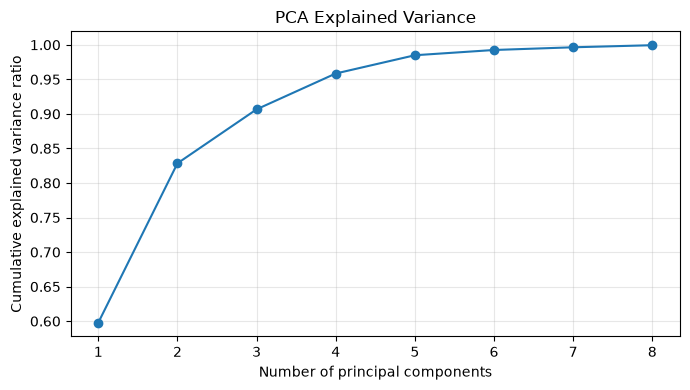

Variance explained by 2 PCs: 0.8285
Variance explained by 4 PCs: 0.9585


In [481]:
# Your code here; add as many cells as you wish

X_scaled_5 = StandardScaler().fit_transform(X_no_bombay)

pca_5 = PCA(n_components=8)
X_pca_5 = pca_5.fit_transform(X_scaled_5)
cumulative_variance = np.cumsum(pca_5.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), cumulative_variance, marker="o")
plt.xticks(range(1, 9))
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance ratio")
plt.title("PCA Explained Variance")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Variance explained by 2 PCs: {cumulative_variance[1]:.4f}")
print(f"Variance explained by 4 PCs: {cumulative_variance[3]:.4f}")

,Cumulative variance,ARI,Silhouette
Components,,,
2,0.8285,0.9972,0.5010
4,0.9585,0.9930,0.4400
6,0.9925,0.9997,0.4288
8,0.9994,0.9988,0.4262


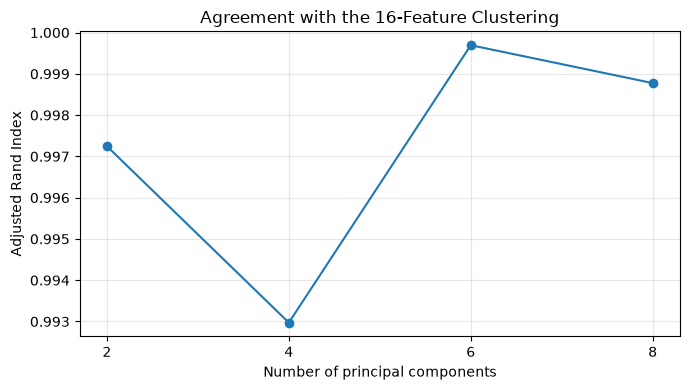

Highest ARI: 0.9997
Components with highest ARI: 6
Component counts with highest silhouette: [2]


In [482]:
component_counts = [2, 4, 6, 8]
pca_results_rows = []

for n in component_counts:
    coordinates = X_pca_5[:, :n]

    model = KMeans(
        n_clusters=best_k_2,
        n_init=10,
        random_state=42,
    )
    labels_pca = model.fit_predict(coordinates)

    ari = adjusted_rand_score(labels_reduced, labels_pca)
    silhouette = silhouette_score(
        coordinates,
        labels_pca,
        sample_size=3000,
        random_state=42,
    )

    pca_results_rows.append({
        "Components": n,
        "Cumulative variance": cumulative_variance[n - 1],
        "ARI": ari,
        "Silhouette": silhouette,
    })

pca_results = pd.DataFrame(pca_results_rows).set_index("Components")
display(pca_results.round(4))

plt.figure(figsize=(7, 4))
plt.plot(pca_results.index, pca_results["ARI"], marker="o")
plt.xticks(component_counts)
plt.xlabel("Number of principal components")
plt.ylabel("Adjusted Rand Index")
plt.title("Agreement with the 16-Feature Clustering")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_pc_count = int(pca_results["ARI"].idxmax())
best_pca_ari = float(pca_results.loc[best_pc_count, "ARI"])

print(f"Highest ARI: {best_pca_ari:.4f}")
print(f"Components with highest ARI: {best_pc_count}")
print(
    "Component counts with highest silhouette:",
    pca_results.index[
        pca_results["Silhouette"] == pca_results["Silhouette"].max()
    ].tolist(),
)

### Problem 5 Graded Questions

In [483]:
# Your answer here, NOT in the next cell

a5a = float(cumulative_variance[1])    # Replace with the proportion of variance explained by 2 PCs.

In [484]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5a = {a5a:.4f}")

a5a = 0.8285


In [485]:
# Your answer here, NOT in the next cell

a5b = float(cumulative_variance[3])    # Replace with the proportion of variance explained by 4 PCs.

In [486]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5b = {a5b:.4f}")

a5b = 0.9585


In [487]:
# Your answer here, NOT in the next cell

a5c = float(pca_results.loc[2, "ARI"])    # Replace with the ARI for 2 PCs.

In [488]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5c = {a5c:.4f}")

a5c = 0.9972


In [489]:
# Your answer here, NOT in the next cell

a5d = float(pca_results.loc[4, "ARI"])    # Replace with the ARI for 4 PCs.

In [490]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5d = {a5d:.4f}")

a5d = 0.9930


In [491]:
# Your answer here, NOT in the next cell

a5e = best_pca_ari    # Replace with the highest PCA-based ARI.

In [492]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5e = {a5e:.4f}")

a5e = 0.9997


In [493]:
# Your answer here, NOT in the next cell

a5f = best_pc_count    # Replace with the number of PCs with the highest ARI.

In [494]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5f = {a5f}")

a5f = 6


# Problem 6: Multiple-Choice Questions

For each question, choose the **single best answer**, and assign its number (`1`, `2`, `3`, or `4`) to the indicated variable. These questions concern the experiments in Problems 1–5. Use your actual numerical results when deciding.

### Part A: What Do the Pairplots Tell Us?

In the exploratory pairplots, beans with unusually large `Area` values appear as a group separated from most of the other observations. A plot colored by known variety shows that these observations are primarily BOMBAY beans. Which conclusion is most justified?

1. The pairplots demonstrate that K-Means must find exactly seven clusters, one for each variety.

2. A distinctive group is visible in some two-dimensional feature projections, suggesting a hypothesis to test with clustering; the plots do not establish that all seven varieties form distinct clusters in the full feature space.

3. Because the pairplots use known variety colors, the K-Means algorithm has been trained on the `Class` column.

4. A visible gap in `Area` guarantees that any clustering algorithm and any feature selection will isolate precisely the same beans.

In [495]:
# Your answer here, NOT in the next cell

a6a = 2    # Replace with the integer 1, 2, 3, or 4.

In [496]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6a = {a6a}")

a6a = 2


### Part B: Removing a Distinctive Population

After removing BOMBAY, the best number of clusters changed from three to two, while the maximum sampled silhouette score increased slightly. What is the most reasonable interpretation?

1. Removing a known variety always increases silhouette scores.

2. The remaining six varieties must correspond to exactly two true biological varieties.

3. The presence of a distinctive population had influenced the clustering structure, and model selection should be reconsidered when the analyzed population changes.

4. The original clustering was invalid because its silhouette score was lower.

In [497]:
# Your answer here, NOT in the next cell

a6b = 3    # Replace with the integer 1, 2, 3, or 4.

In [498]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6b = {a6b}")

a6b = 3


### Part C: Choosing Size or Shape Features

Problem 3 found a higher silhouette score for size features than for shape features, but the two cluster assignments had an ARI well below 1. Which statement is most accurate?

1. Higher silhouette proves that size is more informative than shape for identifying the known varieties.

2. Standardization makes the choice of features irrelevant to K-Means.

3. The two clusterings must be identical because they use the same observations and K.

4. The choice of representation changes which beans are considered similar; a higher silhouette in one feature space does not by itself establish superior agreement with known varieties.

In [499]:
# Your answer here, NOT in the next cell

a6c = 4    # Replace with the integer 1, 2, 3, or 4.

In [500]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6c = {a6c}")

a6c = 4


### Part D: Redundant Features

Problem 4 removed four strongly correlated measurements, yet the new clustering had an ARI near 1 relative to the original. Which conclusion is best supported?

1. The removed measurements contributed little to changing the observed partition in this experiment, although that does not prove they are useless for every analysis.

2. Correlated features can never influence Euclidean distances once standardized.

3. Removing 25% of features must remove exactly 25% of the information.

4. An ARI near 1 means the silhouette scores must also be identical.

In [501]:
# Your answer here, NOT in the next cell

a6d = 1    # Replace with the integer 1, 2, 3, or 4.

In [502]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6d = {a6d}")

a6d = 1


### Part E: PCA Before Clustering

In Problem 5, clustering with two principal components closely reproduced the 16-feature K-Means partition. Which conclusion follows?

1. Two principal components are guaranteed to identify the seven known varieties perfectly.

2. PCA is supervised because the original dataset includes a `Class` column.

3. For this dataset and K, much of the original partition can be recovered in a two-dimensional PCA representation, though this does not imply every downstream task will perform equally well.

4. Keeping more principal components must always strictly increase ARI relative to the original clustering.


In [503]:
# Your answer here, NOT in the next cell

a6e = 3    # Replace with the integer 1, 2, 3, or 4.

In [504]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a6e = {a6e}")

a6e = 3


# Problem 7: Reflection — What Makes a Useful Clustering?

You began with all 16 Dry Bean measurements and seven known varieties, then investigated the effects of removing a distinctive population, changing the feature representation, eliminating correlated features, and applying PCA before clustering.

### Part A: Recommend and Defend a Clustering Strategy

1. **Recommend one configuration** for exploring the structure of the **six non-BOMBAY varieties**. Specify the feature representation (all 16 features, your reduced feature set, size-only, shape-only, or PCA components) and the clustering method and K.
2. Support your recommendation using **at least three specific numerical results** from Problems 2–5. Your evidence should include at least one clustering-quality measure and one comparison of cluster assignments.
3. Explain what the pairplots and the BOMBAY-removal experiment taught you about the relationship between visual groupings, known bean varieties, and clusters discovered without labels.
4. Identify **one limitation** of your chosen strategy. In particular, distinguish agreement with an earlier K-Means partition from evidence that the groups correspond to biologically meaningful bean varieties.

Write **one coherent response of approximately 150–250 words** in `a7a`. There is no single required recommendation; your reasoning and use of evidence matter more than which representation you choose.

In [505]:
# Your answer here, NOT in the next cell

a7a = f"""
I recommend K-Means with K = {best_k_2} using the 12 remaining features
after removing the four redundant measurements, with standardization
before clustering. This configuration retains interpretable measurements
while reducing repeated contributions from strongly correlated features.

The original 16-feature analysis after removing BOMBAY achieved a sampled
silhouette score of {best_score_2:.4f}. The reduced-feature configuration
produced a silhouette score of {score_less:.4f}, a signed difference of
{score_less_diff:.4f}. Its ARI relative to the original partition was
{ari_less_full:.4f}, indicating how closely the assignments were preserved.
Together, these results help assess whether simplifying the representation
substantially changes the grouping. However, the silhouette scores measure
separation in different feature spaces, so their difference is not an
objective ranking of biological usefulness.

The pairplots showed that unusually large beans were primarily BOMBAY,
suggesting a distinctive population worth investigating. Removing that
variety changed the silhouette-selected K from {best_k} to {best_k_2}.
This demonstrates that the analyzed population influences the discovered
structure; visible groups and known varieties do not necessarily correspond
one-to-one with clusters.

A limitation is that agreement with the original K-Means partition only
demonstrates consistency between representations. It does not establish
that either partition identifies biologically meaningful varieties.
Examining cluster composition against the known labels and consulting
domain expertise would be necessary before making that claim.

"""

In [506]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a7a = {a7a}")

a7a = 
I recommend K-Means with K = 2 using the 12 remaining features
after removing the four redundant measurements, with standardization
before clustering. This configuration retains interpretable measurements
while reducing repeated contributions from strongly correlated features.

The original 16-feature analysis after removing BOMBAY achieved a sampled
silhouette score of 0.4261. The reduced-feature configuration
produced a silhouette score of 0.4196, a signed difference of
-0.0065. Its ARI relative to the original partition was
0.9415, indicating how closely the assignments were preserved.
Together, these results help assess whether simplifying the representation
substantially changes the grouping. However, the silhouette scores measure
separation in different feature spaces, so their difference is not an
objective ranking of biological usefulness.

The pairplots showed that unusually large beans were primarily BOMBAY,
suggesting a distinctive population worth investigating. Remo